# Customer Churn — which customers are about to leave?

A telecom operator loses about one customer in four. This notebook predicts which customers are likely to cancel
their subscription, so that the retention team can contact them before they leave.

It follows the whole project from the raw data to the final model and the business recommendations. The code that
is reused (cleaning, pipeline, training, evaluation) lives in the `churn` package (`src/churn`), so the notebook,
the training script and the Streamlit app all run exactly the same steps.

> **Interactive version:** the Streamlit app (`streamlit run app/Home.py`) shows the same work with charts you can
> play with, in English and French.

**Contents**

1. [Problem definition](#1.-Problem-definition)
2. [Setup](#2.-Setup)
3. [Data](#3.-Data)
4. [Exploration](#4.-Exploration)
5. [Preparation](#5.-Preparation)
6. [Model comparison](#6.-Model-comparison)
7. [Final models on the test set](#7.-Final-models-on-the-test-set)
8. [Additional experiments](#8.-Additional-experiments)
9. [Conclusions and recommendations](#9.-Conclusions-and-recommendations)

## 1. Problem definition

- **Data:** the IBM Telco Customer Churn dataset — 7,043 customers, their profile, the services they use, their
  contract and bills, and whether they left during the last month (`Churn`).
- **Task:** binary classification — predict `Churn` (Yes / No).
- **Metric:** only about 26% of customers churn, so accuracy is misleading (always answering "No" already gives 73%).
  Models are ranked by **PR-AUC** (average precision), which measures how well churners are ranked above the
  others. The final decision threshold is then tuned to balance **recall** (share of churners detected) and
  **precision** (share of correct alerts).
- **Method:** several preparation methods and six models are compared in a single, leak-free pipeline, with the
  same cross-validation on the training set. The test set is used only once, at the end.

## 2. Setup

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, display

from churn.config import SEED
from churn.data import CAT_COLS, FEATURES, ID_COL, NUM_COLS, TARGET, clean_data, load_data, split_data
from churn.evaluation import SCORERS, cross_validate_config, make_cv
from churn.pipeline import build_pipeline, experiment_configs
from churn.prediction import load_model, predict
from churn.stats import association, correlation, cramer_ranking, normality
from churn.transformers import GroupMedianImputer

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", font_scale=1.05)
COLORS = {"No": "#2a78d6", "Yes": "#eb6834"}   # colour-blind-safe pair used in every chart

# True = rerun the full training (about 2 minutes); False = read the saved results in artifacts/
RETRAIN = False

## 3. Data

In [2]:
df = load_data()
print(f"{df.shape[0]:,} customers and {df.shape[1]} columns")
df.head()

7,043 customers and 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

- No column contains null values when the file is read.
- Only `SeniorCitizen`, `tenure` and `MonthlyCharges` are read as numbers; the 18 other columns are text.
- `SeniorCitizen` is numeric (0/1) but it is a **categorical** variable.
- `TotalCharges` should be numeric but is read as text: some values cannot be converted (see below).

### 3.1 Dropping `customerID`

In [4]:
df[ID_COL].nunique() == len(df)

True

`customerID` takes a different value on every row: it is a unique identifier. It says nothing about the customer's
behaviour, and a model could only learn it by heart, so it is **dropped** before modelling (`clean_data` does it).

### 3.2 Cleaning `TotalCharges`

In [5]:
total = pd.to_numeric(df["TotalCharges"], errors="coerce")
bad = df[total.isna()]
print(f"{len(bad)} values cannot be converted:", bad["TotalCharges"].unique())
bad[[ID_COL, "tenure", "Contract", "MonthlyCharges", "TotalCharges"]]

11 values cannot be converted: <ArrowStringArray>
[' ']
Length: 1, dtype: str


,customerID,tenure,Contract,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,Two year,52.55,
753,3115-CZMZD,0,Two year,20.25,
936,5709-LVOEQ,0,Two year,80.85,
1082,4367-NUYAO,0,Two year,25.75,
1340,1371-DWPAZ,0,Two year,56.05,
3331,7644-OMVMY,0,Two year,19.85,
3826,3213-VVOLG,0,Two year,25.35,
4380,2520-SGTTA,0,Two year,20.00,
5218,2923-ARZLG,0,One year,19.70,
6670,4075-WKNIU,0,Two year,73.35,


The 11 values that cannot be converted are a **blank space** (`' '`). They become missing values (NaN).

**These 11 customers all have `tenure = 0`:** they joined during the current month and have not been billed yet,
so their real total is 0. The pipeline offers three ways to fill these values (0, overall median, or median by
contract type and online security) and the comparison decides which one works best.

### 3.3 Duplicated rows

In [6]:
features = df.drop(columns=ID_COL)
dups = features[features.duplicated(keep=False)]
print(f"{features.duplicated().sum()} rows are identical to another one on every feature")
print("tenure of these rows:", dups["tenure"].unique())

22 rows are identical to another one on every feature
tenure of these rows: [1]


The 22 duplicated rows are **different customers** (different IDs) with exactly the same profile, all with
`tenure = 1`: new customers on standard offers. They are real observations, so they are **kept** by default
(`clean_data(drop_duplicates=True)` removes them if needed).

## 4. Exploration

The exploration uses the cleaned data with readable labels (`customerID` dropped, `TotalCharges` numeric,
`SeniorCitizen` as No/Yes).

In [7]:
eda = df.drop(columns=ID_COL)
eda["TotalCharges"] = pd.to_numeric(eda["TotalCharges"], errors="coerce")
eda["SeniorCitizen"] = eda["SeniorCitizen"].map({0: "No", 1: "Yes"})
churn01 = (eda[TARGET] == "Yes").astype(int)
eda[NUM_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7032.0,2283.30,2266.77,18.80,401.45,1397.48,3794.74,8684.80


In [8]:
eda[CAT_COLS].describe().T

,count,unique,top,freq
gender,7043,2,Male,3555
SeniorCitizen,7043,2,No,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


- The three numeric features have very different scales (`TotalCharges` goes from about 19 to 8,685), so they
  need **scaling**, and their distributions are skewed, so a **transformation** is worth trying.
- Categorical features have a **low cardinality** (2 to 4 values): one-hot encoding is simple and appropriate.

### 4.1 Target: `Churn`

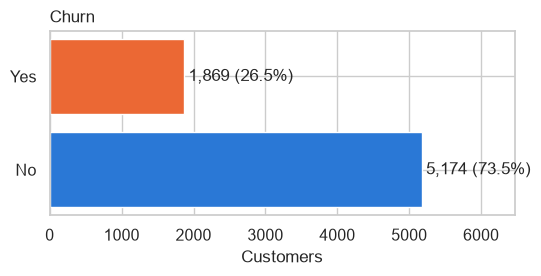

In [9]:
counts = eda[TARGET].value_counts()
fig, ax = plt.subplots(figsize=(6, 2.4))
ax.barh(counts.index, counts.values, color=[COLORS[c] for c in counts.index])
for i, (label, n) in enumerate(counts.items()):
    ax.text(n + 60, i, f"{n:,} ({n / len(eda):.1%})", va="center")
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xlabel("Customers")
ax.set_title("Churn", loc="left")
plt.show()

About **one customer in four left** (26.5%). The classes are **imbalanced**: a model that always predicts "No"
would already be right 73% of the time, which is why accuracy alone is not a good metric here.

### 4.2 Categorical features

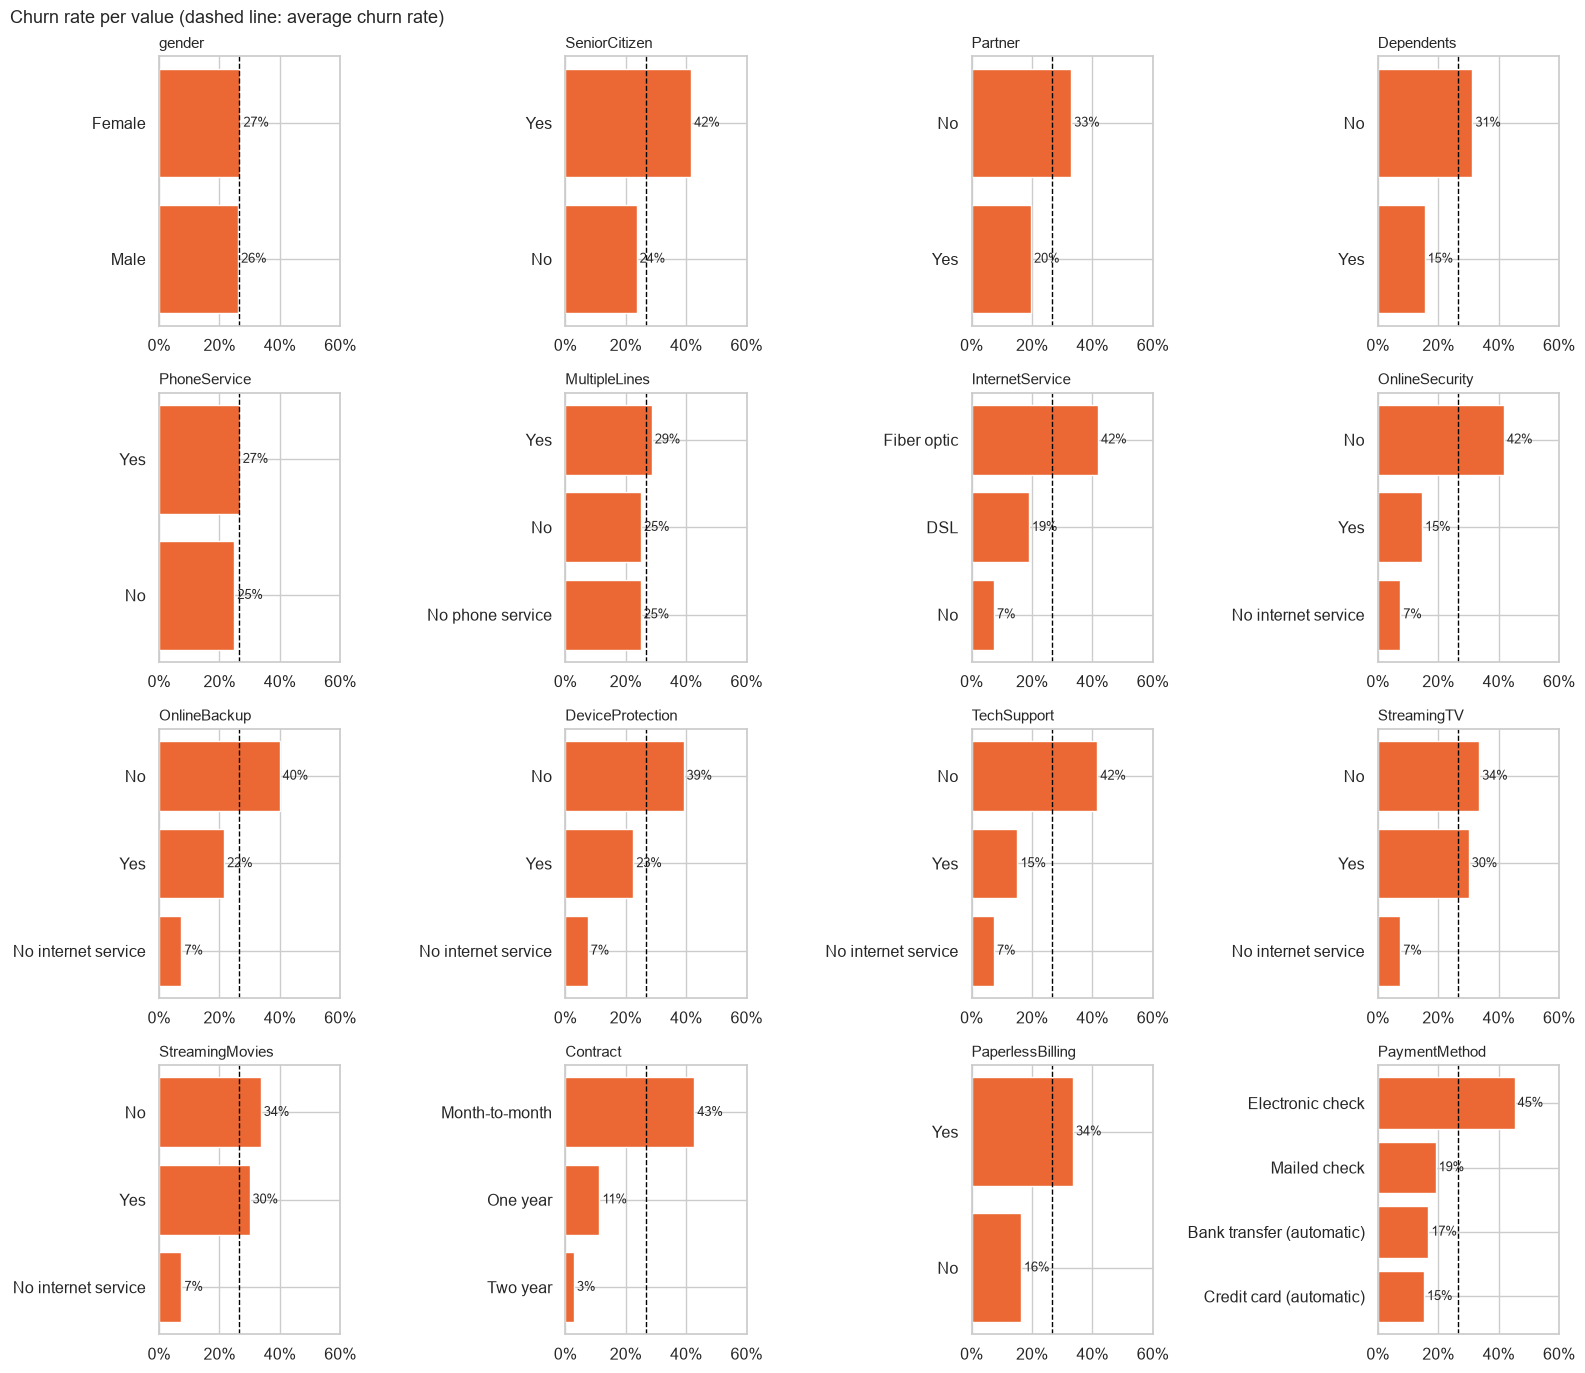

In [10]:
overall = churn01.mean()
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
for ax, feature in zip(axes.flat, CAT_COLS):
    rate = churn01.groupby(eda[feature]).mean().sort_values()
    ax.barh(rate.index.astype(str), rate.values, color=COLORS["Yes"])
    ax.axvline(overall, color="black", ls="--", lw=1)
    for i, v in enumerate(rate.values):
        ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9)
    ax.set_xlim(0, 0.6)
    ax.set_title(feature, loc="left", fontsize=11)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
fig.suptitle("Churn rate per value (dashed line: average churn rate)", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

- **Contract:** 43% of month-to-month customers leave, against 11% with a one-year contract and 3% with a two-year
  contract.
- **Support services:** customers without online security or tech support churn far more than those with it.
- **Fiber optic** customers and **electronic check** payers are the most exposed.
- **Gender** and **phone service** make almost no difference.

In [11]:
tests = pd.DataFrame({f: association(eda, f, TARGET) for f in CAT_COLS}).T
tests = tests.sort_values("cramer_v", ascending=False)
tests.style.format({"chi2": "{:.1f}", "p_value": "{:.2e}", "cramer_v": "{:.3f}", "tschuprow_t": "{:.3f}"})

,chi2,p_value,cramer_v,tschuprow_t
Contract,1184.6,5.86e-258,0.410,0.345
OnlineSecurity,850.0,2.66e-185,0.347,0.292
TechSupport,828.2,1.44e-180,0.343,0.288
InternetService,732.3,9.57e-160,0.322,0.271
PaymentMethod,648.1,3.68e-140,0.303,0.231
OnlineBackup,601.8,2.08e-131,0.292,0.246
DeviceProtection,558.4,5.51e-122,0.282,0.237
StreamingMovies,375.7,2.67e-82,0.231,0.194
StreamingTV,374.2,5.53e-82,0.231,0.194
PaperlessBilling,258.3,4.07e-58,0.191,0.191


**Chi-squared test of independence** between each feature and `Churn`, with **Cramér's V** (strength of the
association, from 0 = none to 1 = perfect). Only `gender` and `PhoneService` have a p-value above 0.05: for them,
independence from churn cannot be rejected.

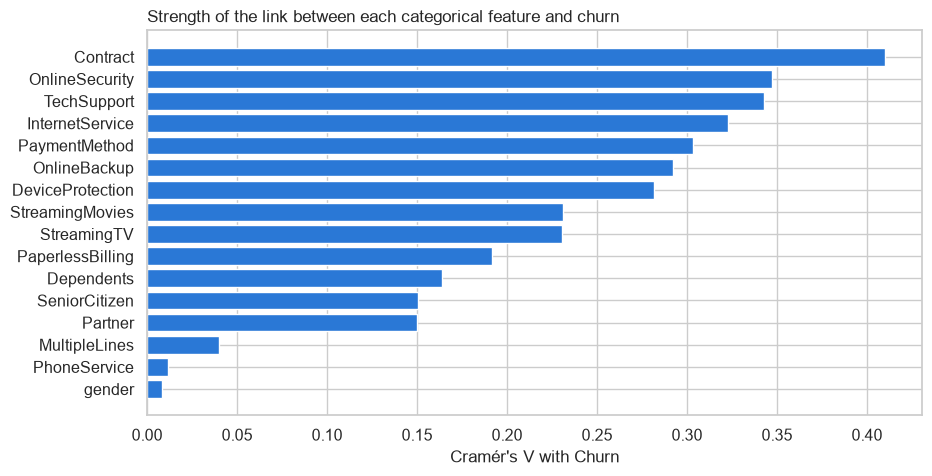

In [12]:
ranking = cramer_ranking(eda, CAT_COLS, TARGET)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(ranking.feature[::-1], ranking.cramer_v[::-1], color="#2a78d6")
ax.set_xlabel("Cramér's V with Churn")
ax.set_title("Strength of the link between each categorical feature and churn", loc="left")
plt.show()

`Contract`, `OnlineSecurity` and `TechSupport` are the most linked to churn; `gender` and `PhoneService` are not
linked at all.

In [13]:
for a, b in [("StreamingMovies", "StreamingTV"), ("Partner", "SeniorCitizen")]:
    r = association(eda, a, b)
    print(f"{a} vs {b}: Cramér's V = {r['cramer_v']:.2f}, p-value = {r['p_value']:.2g}")

StreamingMovies vs StreamingTV: Cramér's V = 0.77, p-value = 0
Partner vs SeniorCitizen: Cramér's V = 0.02, p-value = 0.18


`StreamingMovies` and `StreamingTV` have almost the same link with churn because they are **strongly associated
with each other** (Cramér's V = 0.77): customers usually take both or neither. `Partner` and `SeniorCitizen`, which
also look alike in the ranking, are only weakly associated: they carry different information.

### 4.3 Numeric features

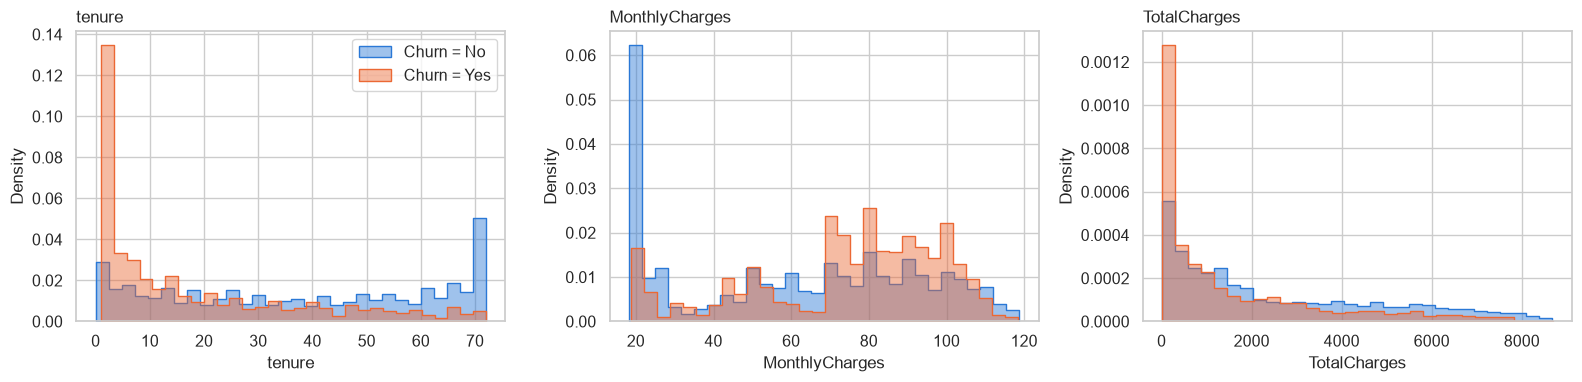

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, feature in zip(axes, NUM_COLS):
    for label in ["No", "Yes"]:
        sns.histplot(eda.loc[eda[TARGET] == label, feature], bins=30, ax=ax, color=COLORS[label],
                     label=f"Churn = {label}", stat="density", alpha=0.45, element="step")
    ax.set_title(feature, loc="left")
axes[0].legend()
plt.tight_layout()
plt.show()

In [15]:
pd.DataFrame({f: normality(eda[f]) for f in NUM_COLS}).T.style.format("{:.3g}")

,skewness,kurtosis,dagostino_p,ks_p,shapiro_p
tenure,0.24,-1.39,0,4.66e-76,1.64e-48
MonthlyCharges,-0.221,-1.26,0,3.15e-98,2.83e-45
TotalCharges,0.962,-0.232,9.61e-176,1.47e-155,2.01e-55


- None of the three features is normally distributed (all normality tests have p-values close to 0).
  `TotalCharges` is strongly right-skewed; `tenure` has two peaks (new customers and very loyal customers).
- Customers who leave have a **short tenure**: their distribution is concentrated in the first months.

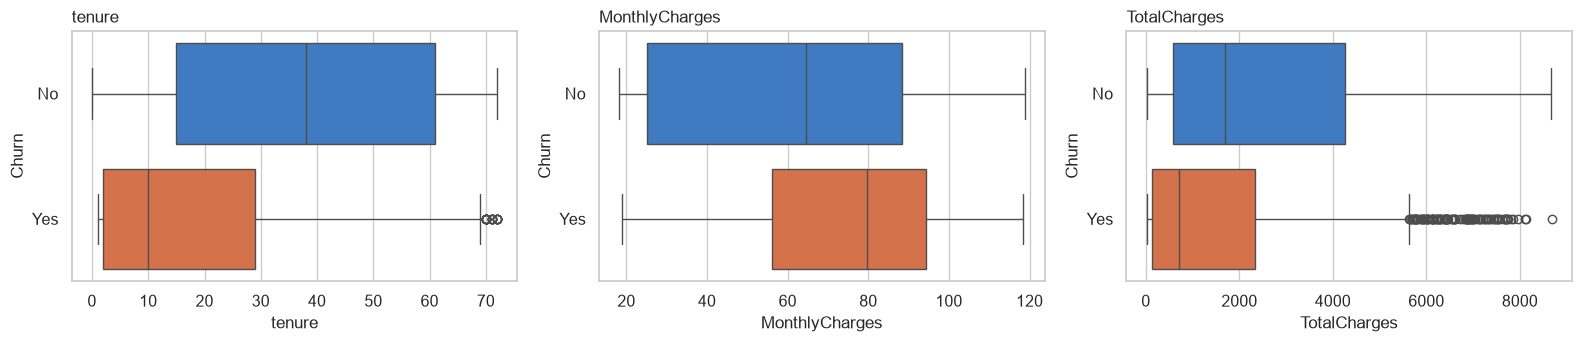

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, feature in zip(axes, NUM_COLS):
    sns.boxplot(data=eda, x=feature, y=TARGET, hue=TARGET, palette=COLORS, ax=ax, legend=False)
    ax.set_title(feature, loc="left")
plt.tight_layout()
plt.show()

The boxplots show no point beyond the whiskers: there are **no outliers** to treat. They also confirm the gap in
tenure: churners have a median tenure of about 10 months, against 38 for the others.

In [17]:
churners = eda[eda[TARGET] == "Yes"]
print(f"{(churners.tenure < 12).mean():.0%} of the customers who leave do so during their first year")
eda.groupby(["Contract", TARGET])["tenure"].median().unstack().rename(columns=lambda c: f"median tenure, Churn = {c}")

53% of the customers who leave do so during their first year


Churn,"median tenure, Churn = No","median tenure, Churn = Yes"
Contract,,
Month-to-month,16.0,7.0
One year,43.0,48.0
Two year,64.0,65.5


- **53% of the customers who leave do so during their first year:** the first months are the period of highest risk.
- For **month-to-month** contracts, churners leave early (median 7 months, against 16 for the customers who stay).
  For one- and two-year contracts, churners have a *longer* tenure than the others: they tend to leave **at the end
  of their contract**.

In [18]:
corr = pd.DataFrame({m: {f: correlation(eda[f].fillna(0), churn01, m)[0] for f in NUM_COLS}
                     for m in ["pearson", "spearman", "kendall"]})
corr.style.format("{:.3f}").background_gradient(cmap="RdBu_r", vmin=-0.5, vmax=0.5)

,pearson,spearman,kendall
tenure,-0.352,-0.367,-0.303
MonthlyCharges,0.193,0.185,0.151
TotalCharges,-0.198,-0.230,-0.188


- `tenure` and `TotalCharges` are **negatively** correlated with churn (long-standing customers stay), while
  `MonthlyCharges` is **positively** correlated (higher bills, more departures).
- `tenure` has the strongest link. The three coefficients (Pearson, Spearman, Kendall) agree on the direction.

## 5. Preparation

Every step that **learns** something from the data (medians, transformation parameters, scaling, resampling) is
part of a single pipeline. The data is split first; the pipeline is then fitted on the training set only, and
inside the cross-validation it is refitted on each training fold. Resampling (oversampling, undersampling, SMOTE)
is applied to training folds only, never to the data used for evaluation.

### 5.1 Train / test split

In [19]:
X, y = clean_data(df)                       # drop customerID, TotalCharges -> number, Churn -> 0/1
X_train, X_test, y_train, y_test = split_data(X, y)   # stratified 80 / 20
pd.DataFrame({"rows": [len(X_train), len(X_test)], "churn rate": [y_train.mean(), y_test.mean()]},
             index=["train", "test"]).style.format({"rows": "{:,}", "churn rate": "{:.1%}"})

,rows,churn rate
train,"5,634",26.5%
test,"1,409",26.5%


The split is stratified: the churn rate is the same in both sets. The test set is not used again until section 7.

### 5.2 Missing values: median by group

In [20]:
imputer = GroupMedianImputer().fit(X_train)
imputer.medians_.unstack().round(1)

OnlineSecurity,No,No internet service,Yes
Contract,,,
Month-to-month,786.3,107.0,1501.6
One year,3503.5,534.7,3665.6
Two year,5329.6,1148.8,5589.4


`GroupMedianImputer` (a scikit-learn compatible transformer, see `src/churn/transformers.py`) learns the median of
`TotalCharges` for each combination of **contract type** (rows) and **online security** (columns), on the training
data only. Two other strategies are compared: the overall median and the constant 0 (the real value for these new
customers).

### 5.3 Transformation of numeric features

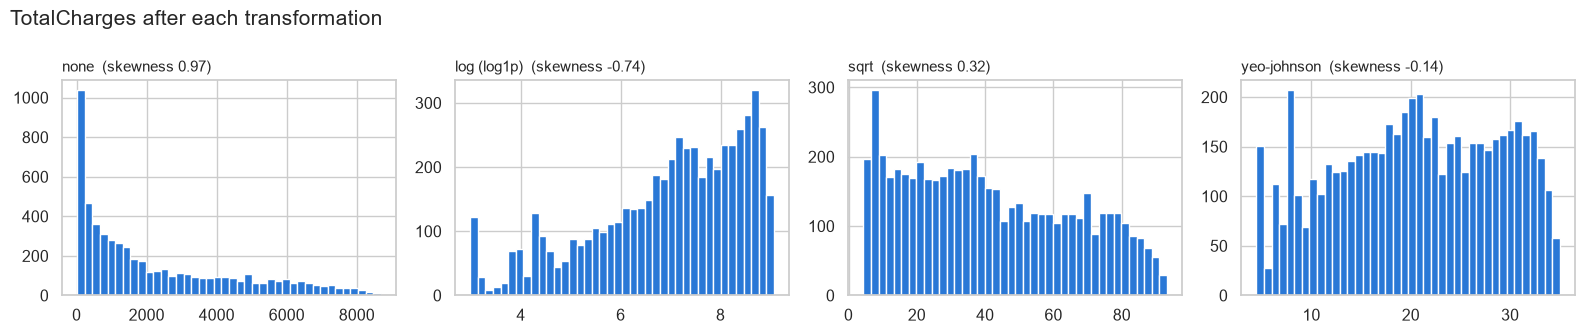

In [21]:
from sklearn.preprocessing import PowerTransformer

x = X_train["TotalCharges"].dropna().to_frame()
variants = {"none": x.squeeze(), "log (log1p)": np.log1p(x.squeeze()), "sqrt": np.sqrt(x.squeeze()),
            "yeo-johnson": pd.Series(PowerTransformer(standardize=False).fit_transform(x).ravel())}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (name, values) in zip(axes, variants.items()):
    ax.hist(values, bins=40, color="#2a78d6")
    ax.set_title(f"{name}  (skewness {values.skew():.2f})", loc="left", fontsize=11)
plt.suptitle("TotalCharges after each transformation", x=0.01, ha="left")
plt.tight_layout()
plt.show()

The transformations reduce the skewness of `TotalCharges` (the square root and Yeo-Johnson bring it close to 0) but
none makes it normal. They matter for linear models, not for tree-based models, which only use the order of the
values. `log1p` is used rather than `log` because `tenure` can be 0 and log(0) is −∞.

### 5.4 Encoding

In [22]:
prep = build_pipeline(model="logistic_regression", transform="log", scaler="robust")[:2].fit(X_train)
names = prep.named_steps["preprocess"].get_feature_names_out()
print(f"{len(FEATURES)} original features -> {len(names)} columns after encoding")
pd.DataFrame(prep.transform(X_train.head(5)), columns=names).round(2)

19 original features -> 40 columns after encoding


,tenure,MonthlyCharges,TotalCharges,gender_Male,SeniorCitizen_1,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,...,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0.37,-0.48,0.27,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
1,-0.36,-1.36,-0.64,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.41,0.49,0.70,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
3,0.14,0.40,0.42,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
4,0.00,0.01,0.16,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


`OneHotEncoder(drop="if_binary")` turns binary features into a single 0/1 column and the others into one column per
value. `handle_unknown="ignore"` keeps the model working if a new value appears at prediction time.

### 5.5 Scaling

In [23]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

num = X_train[NUM_COLS].fillna(0)
summary = {name: pd.DataFrame(s.fit_transform(num), columns=NUM_COLS).agg(["mean", "std", "min", "max"]).round(2)
           for name, s in {"standard": StandardScaler(), "minmax": MinMaxScaler(), "robust": RobustScaler()}.items()}
pd.concat(summary, axis=1)

standard                             minmax                              \
       tenure MonthlyCharges TotalCharges tenure MonthlyCharges TotalCharges   
mean     0.00           0.00         0.00   0.45           0.46         0.26   
std      1.00           1.00         1.00   0.34           0.30         0.26   
min     -1.32          -1.54        -1.01   0.00           0.00         0.00   
max      1.62           1.80         2.84   1.00           1.00         1.00   

     robust                              
     tenure MonthlyCharges TotalCharges  
mean   0.07          -0.10         0.26  
std    0.53           0.55         0.67  
min   -0.63          -0.96        -0.41  
max    0.93           0.89         2.17

- **StandardScaler:** mean 0, standard deviation 1.
- **MinMaxScaler:** values between 0 and 1.
- **RobustScaler:** centred on the median and divided by the interquartile range, so it is less sensitive to extreme
  values.

### 5.6 Class imbalance

In [24]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

Xt = prep.transform(X_train)
sizes = {"none": np.bincount(y_train)}
for name, sampler in {"over": RandomOverSampler(random_state=SEED), "under": RandomUnderSampler(random_state=SEED),
                      "smote": SMOTE(random_state=SEED)}.items():
    sizes[name] = np.bincount(sampler.fit_resample(Xt, y_train)[1])
pd.DataFrame(sizes, index=["No churn", "Churn"]).T

,No churn,Churn
none,4139,1495
over,4139,4139
under,1495,1495
smote,4139,4139


Four strategies are compared with the option of doing nothing:

- **class_weight="balanced":** errors on churners weigh more in training, no row is added or removed.
- **over:** churners are duplicated at random until both classes have the same size.
- **under:** non-churners are removed at random (less data).
- **SMOTE:** new synthetic churners are created between existing neighbours.

Resampling is a pipeline step (`imblearn.pipeline.Pipeline`), so it only runs during `fit`.

### 5.7 The complete pipeline

In [25]:
pipeline = build_pipeline(model="logistic_regression", imputer="group_median",
                          transform="log", scaler="robust", imbalance="smote")
pipeline

,steps,"[('group_impute', ...), ('preprocess', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,column,'TotalCharges'
,groupby,"('Contract', ...)"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term

## 6. Model comparison

Each combination = imputation × numeric transformation × scaler × imbalance strategy × model. Tree-based models are
insensitive to monotonic transformations and to scaling, so only the imputation and imbalance strategies are varied
for them. Every combination is evaluated with the same **5-fold stratified cross-validation on the training set**.

Then, for each of the six models, the best combination is tuned (`GridSearchCV`), its decision threshold is tuned
(`TunedThresholdClassifierCV`, F1 criterion), and the final model is evaluated once on the test set. All of this is
done by `churn.train.train()`; set `RETRAIN = True` in the setup cell to rerun it.

In [26]:
import json

from churn.config import METRICS_PATH, RESULTS_PATH, TEST_PREDICTIONS_PATH, IMPORTANCE_PATH, COEFFICIENTS_PATH

if RETRAIN:
    from churn.train import train
    train(metric="average_precision", threshold_metric="f1")

results = pd.read_csv(RESULTS_PATH)
with open(METRICS_PATH, encoding="utf-8") as f:
    metrics = json.load(f)
print(f"{len(results)} combinations compared; reference without a model (always 'no churn'): "
      f"PR-AUC = {metrics['baseline_cv']['average_precision']:.3f}")

83 combinations compared; reference without a model (always 'no churn'): PR-AUC = 0.265


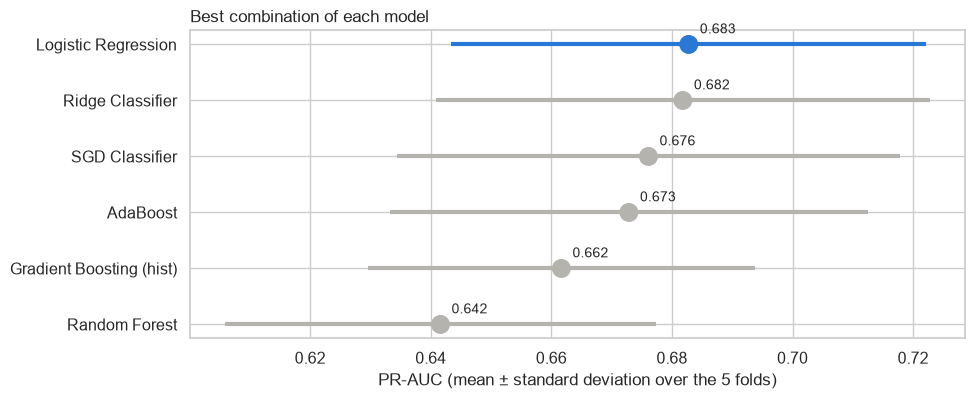

,model,imputer,transform,scaler,imbalance,average_precision,average_precision_std,roc_auc,recall,precision,f1
0,logistic_regression,group_median,log,robust,none,0.683,0.039,0.857,0.549,0.674,0.605
6,ridge,group_median,log,robust,class_weight,0.682,0.041,0.856,0.549,0.672,0.604
32,sgd,group_median,yeo-johnson,standard,smote,0.676,0.042,0.852,0.826,0.503,0.623
37,adaboost,group_median,none,standard,none,0.673,0.040,0.854,0.562,0.664,0.608
64,hist_gradient_boosting,group_median,none,standard,none,0.662,0.032,0.843,0.551,0.650,0.596
79,random_forest,group_median,none,standard,none,0.642,0.036,0.831,0.512,0.645,0.571


In [27]:
MODEL_NAMES = {"logistic_regression": "Logistic Regression", "ridge": "Ridge Classifier", "sgd": "SGD Classifier",
               "random_forest": "Random Forest", "hist_gradient_boosting": "Gradient Boosting (hist)",
               "adaboost": "AdaBoost"}
cols = ["model", "imputer", "transform", "scaler", "imbalance", "average_precision", "average_precision_std",
        "roc_auc", "recall", "precision", "f1"]
best = results.sort_values("average_precision", ascending=False).groupby("model", sort=False).head(1)[cols]

fig, ax = plt.subplots(figsize=(10, 4))
labels = best.model.map(MODEL_NAMES)[::-1]
colors = ["#2a78d6" if m == best.model.iloc[0] else "#b4b3ad" for m in best.model[::-1]]
ax.errorbar(best.average_precision[::-1], labels, xerr=best.average_precision_std[::-1], fmt="none",
            ecolor=colors, elinewidth=3)
ax.scatter(best.average_precision[::-1], labels, s=160, color=colors, zorder=3)
for v, lab in zip(best.average_precision[::-1], labels):
    ax.annotate(f"{v:.3f}", (v, lab), xytext=(8, 8), textcoords="offset points", fontsize=10)
ax.set_xlabel("PR-AUC (mean ± standard deviation over the 5 folds)")
ax.set_title("Best combination of each model", loc="left")
plt.show()
best.round(3)

The six models end up **very close to each other**: the error bars (variation between folds) overlap widely, so no
model is clearly better. **Logistic Regression** has the best mean score in cross-validation and is selected; it is
also the simplest model to explain.

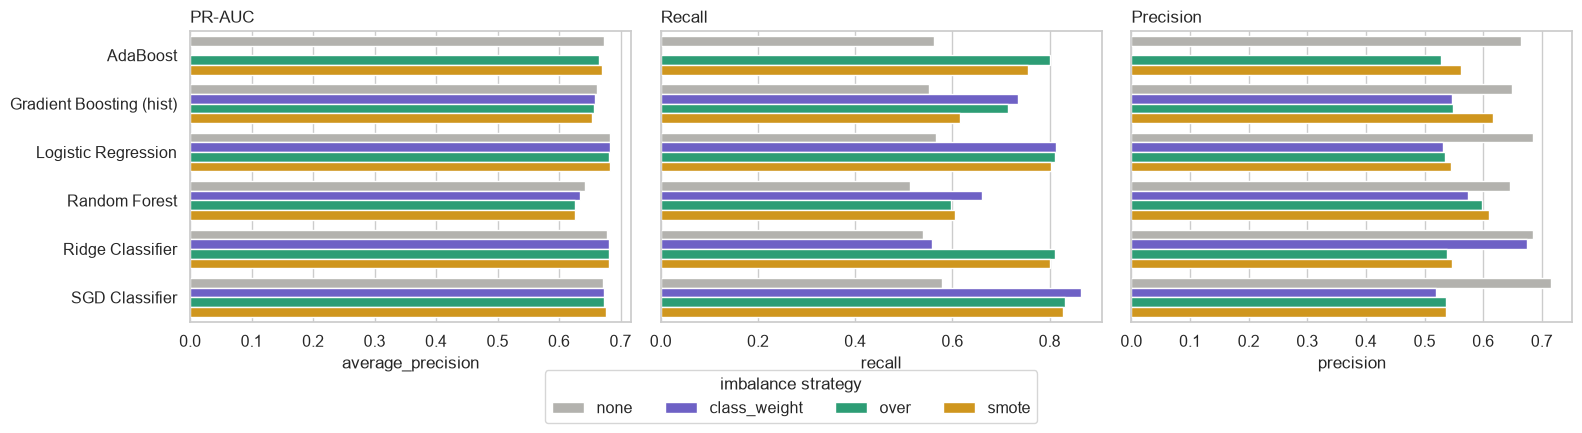

In [28]:
imb = results.groupby(["model", "imbalance"])[["average_precision", "recall", "precision"]].max().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
order = ["none", "class_weight", "over", "smote"]
for ax, metric in zip(axes, ["average_precision", "recall", "precision"]):
    sns.barplot(data=imb, x=metric, y=imb.model.map(MODEL_NAMES), hue="imbalance", hue_order=order, ax=ax,
                palette=["#b4b3ad", "#6250d6", "#1baf7a", "#eda100"])
    ax.set_ylabel("")
    ax.set_title({"average_precision": "PR-AUC", "recall": "Recall", "precision": "Precision"}[metric], loc="left")
    handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()
fig.legend(handles, labels, title="imbalance strategy", loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()

The imbalance strategies **barely change the PR-AUC** (how well churners are ranked), but they move the
**recall / precision trade-off** at the default threshold of 0.5: with them, the models detect many more churners at
the cost of more false alarms. Tuning the decision threshold (next section) reaches the same trade-off without
modifying the training data.

In [29]:
final = pd.DataFrame({MODEL_NAMES[n]: {**s["config"], "hyperparameters": s["params"], "PR-AUC (CV)": s["cv_score"],
                                       "threshold": s["threshold"]} for n, s in metrics["models"].items()}).T
final.round(3)

,model,imputer,transform,scaler,imbalance,hyperparameters,PR-AUC (CV),threshold
Logistic Regression,logistic_regression,group_median,log,robust,none,{'model__C': 0.1},0.682782,0.376182
Ridge Classifier,ridge,group_median,log,robust,class_weight,{'model__estimator__alpha': 10},0.681887,0.335771
SGD Classifier,sgd,group_median,yeo-johnson,standard,smote,"{'model__alpha': 0.001, 'model__penalty': 'l1'}",0.678182,0.57792
AdaBoost,adaboost,group_median,none,standard,none,"{'model__learning_rate': 0.5, 'model__n_estima...",0.675071,0.4613
Gradient Boosting (hist),hist_gradient_boosting,group_median,none,standard,none,"{'model__l2_regularization': 0, 'model__learni...",0.679069,0.373894
Random Forest,random_forest,group_median,none,standard,none,"{'model__max_depth': None, 'model__min_samples...",0.675021,0.337772


## 7. Final models on the test set

The 1,409 test customers were set aside at the start and never used for training or for choosing the model.

In [30]:
test = pd.DataFrame({MODEL_NAMES[n]: {**s["test"], "threshold": s["threshold"]} for n, s in metrics["models"].items()}).T
test.style.format("{:.3f}").highlight_max(axis=0, color="#cde2fb")

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,threshold
Logistic Regression,0.766,0.719,0.552,0.620,0.584,0.825,0.628,0.376
Ridge Classifier,0.756,0.731,0.531,0.679,0.596,0.823,0.627,0.336
SGD Classifier,0.764,0.732,0.545,0.663,0.598,0.823,0.628,0.578
AdaBoost,0.766,0.723,0.551,0.631,0.589,0.824,0.622,0.461
Gradient Boosting (hist),0.760,0.722,0.541,0.642,0.587,0.824,0.627,0.374
Random Forest,0.757,0.733,0.533,0.682,0.599,0.822,0.620,0.338


On customers it has never seen, the selected Logistic Regression detects **62% of the customers who leave**, and
**55% of its alerts are correct**. The ROC-AUC (0.82) and PR-AUC (0.63) are far above the reference without a
model (0.50 and 0.27). The other models give very similar results.

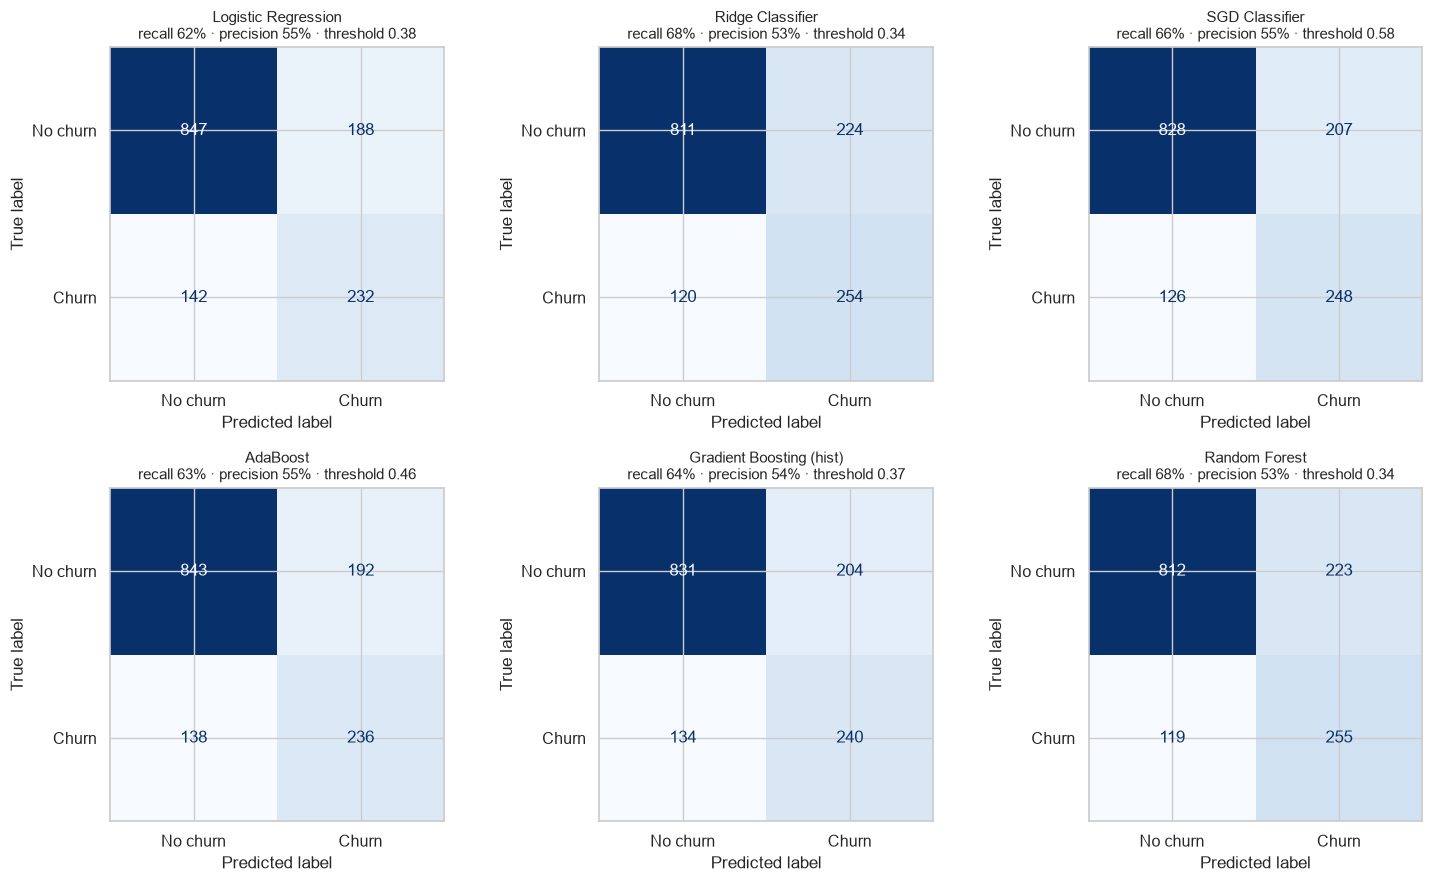

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, s) in zip(axes.flat, metrics["models"].items()):
    ConfusionMatrixDisplay(np.array(s["confusion_matrix"]), display_labels=["No churn", "Churn"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{MODEL_NAMES[name]}\nrecall {s['test']['recall']:.0%} · precision {s['test']['precision']:.0%} · "
                 f"threshold {s['threshold']:.2f}", fontsize=11)
plt.tight_layout()
plt.show()

Each matrix splits the test customers into four groups: **caught churners** (bottom right), **missed churners**
(bottom left), **false alarms** (top right) and customers **correctly left alone** (top left).

### 7.1 Decision threshold

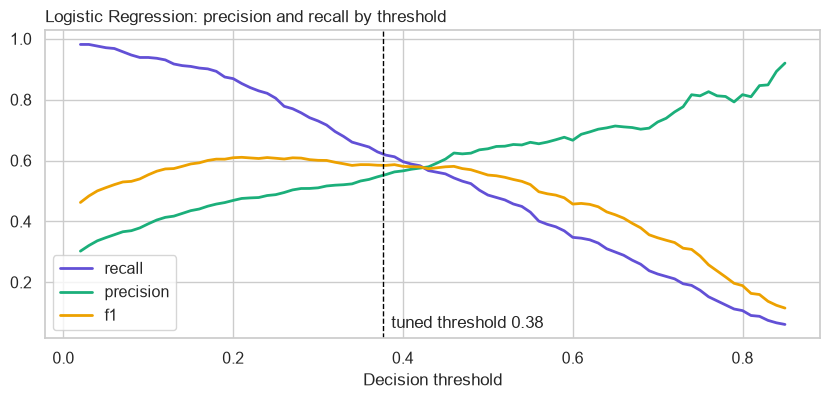

threshold 0.50: recall 49%, precision 64%
threshold 0.38: recall 62%, precision 55%


In [32]:
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, f1_score

preds = pd.read_csv(TEST_PREDICTIONS_PATH)
selected = metrics["selected_model"]
proba, y_true = preds[selected], preds["y_true"]
thr = metrics["models"][selected]["threshold"]

grid = np.arange(0.02, 0.98, 0.01)
rows = []
for t in grid:
    flagged = proba >= t
    if flagged.sum() < 20:      # beyond this point precision is computed on too few customers
        break
    p = flagged.astype(int)
    rows.append((t, recall_score(y_true, p), precision_score(y_true, p), f1_score(y_true, p)))
curves = pd.DataFrame(rows, columns=["threshold", "recall", "precision", "f1"])

fig, ax = plt.subplots(figsize=(10, 4))
for metric, color in zip(["recall", "precision", "f1"], ["#6250d6", "#1baf7a", "#eda100"]):
    ax.plot(curves.threshold, curves[metric], color=color, lw=2, label=metric)
ax.axvline(thr, color="black", ls="--", lw=1)
ax.text(thr + 0.01, 0.05, f"tuned threshold {thr:.2f}")
ax.set_xlabel("Decision threshold")
ax.legend()
ax.set_title(f"{MODEL_NAMES[selected]}: precision and recall by threshold", loc="left")
plt.show()

s = metrics["models"][selected]
print(f"threshold 0.50: recall {s['test_threshold_0.5']['recall']:.0%}, precision {s['test_threshold_0.5']['precision']:.0%}")
print(f"threshold {thr:.2f}: recall {s['test']['recall']:.0%}, precision {s['test']['precision']:.0%}")

With the default threshold of 0.5, the model detects only **49%** of churners. Lowering the threshold to the value
tuned in cross-validation raises recall to **62%**, with a moderate loss of precision (64% → 55%). For a retention
campaign, missing a churner usually costs more than contacting a customer who would have stayed.

### 7.2 Precision-recall curves

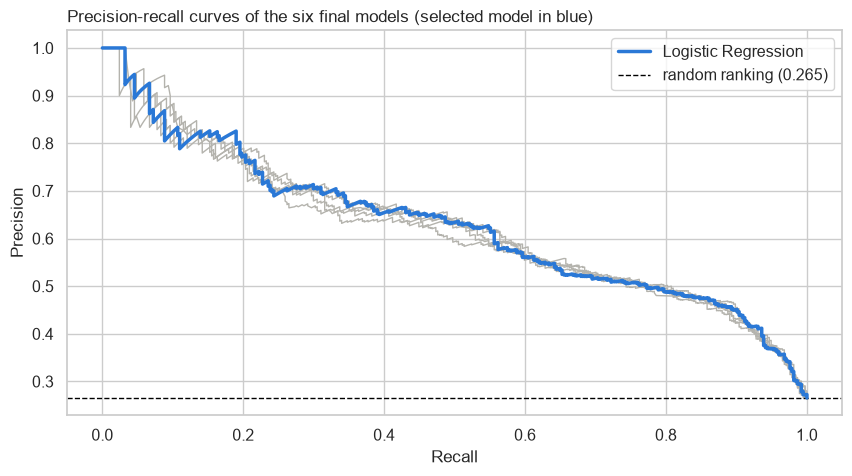

In [33]:
fig, ax = plt.subplots(figsize=(10, 5))
for name in MODEL_NAMES:
    p, r, _ = precision_recall_curve(y_true, preds[name])
    focus = name == selected
    ax.plot(r, p, color="#2a78d6" if focus else "#b4b3ad", lw=2.5 if focus else 1, zorder=3 if focus else 1,
            label=MODEL_NAMES[name] if focus else None)
ax.axhline(y_true.mean(), color="black", ls="--", lw=1, label=f"random ranking ({y_true.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
ax.set_title("Precision-recall curves of the six final models (selected model in blue)", loc="left")
plt.show()

The six curves almost overlap: **the models are practically equivalent** on this dataset. All of them are far above
the dashed line, which is what a random ranking would give.

### 7.3 Which features matter

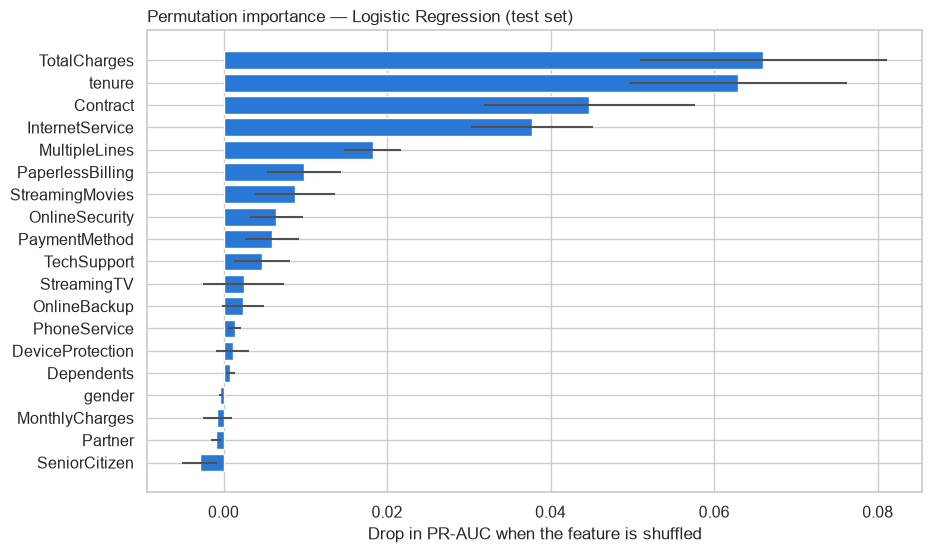

In [34]:
imp = pd.read_csv(IMPORTANCE_PATH)
sel = imp[imp.model == selected].sort_values("importance", ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(sel.feature[::-1], sel.importance[::-1], xerr=sel["std"][::-1], color="#2a78d6", ecolor="#52514e")
ax.set_xlabel("Drop in PR-AUC when the feature is shuffled")
ax.set_title(f"Permutation importance — {MODEL_NAMES[selected]} (test set)", loc="left")
plt.show()

**Permutation importance** measures how much the PR-AUC drops when the values of one feature are shuffled. It is
computed the same way for every model, on the original features. `TotalCharges`, `tenure`, `Contract` and
`InternetService` carry most of the information; `gender` and `PhoneService` bring nothing, as the exploration
suggested.

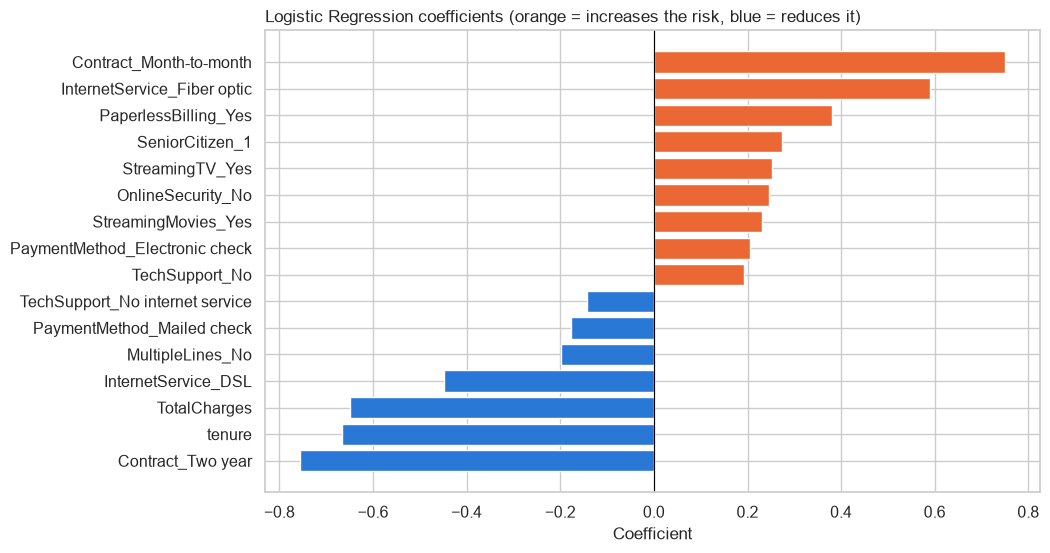

In [35]:
coefs = pd.read_csv(COEFFICIENTS_PATH)
shown = pd.concat([coefs.head(9), coefs.tail(7)])
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(shown.feature[::-1], shown.coefficient[::-1],
        color=["#eb6834" if c > 0 else "#2a78d6" for c in shown.coefficient[::-1]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Coefficient")
ax.set_title("Logistic Regression coefficients (orange = increases the risk, blue = reduces it)", loc="left")
plt.show()

The coefficients of the logistic regression give the **direction** of each effect (numeric features are transformed
and scaled, so only their sign and order are compared): a month-to-month contract, fiber optic and paperless billing
increase the risk; a two-year contract and a long tenure reduce it.

### 7.4 Using the model

In [36]:
customer = {
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 6,
    "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic", "OnlineSecurity": "No",
    "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "No",
    "StreamingMovies": "No", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check", "MonthlyCharges": 80.0, "TotalCharges": 480.0,
}
predict([customer], load_model(selected))

,churn_probability,churn
0,0.62025,True


A new customer on a month-to-month contract, with fiber optic, no support services and paying by electronic check,
is above the decision threshold: they would be passed on to the retention team.

## 8. Additional experiments

Other ideas tried on top of the main comparison: feature selection, dimensionality reduction, a stacked model and a
neural network. Each one starts from the selected configuration (Logistic Regression, median by group, log, robust
scaler) and is evaluated with the **same 5-fold cross-validation on the training set**, so the scores are directly
comparable with the reference.

In [37]:
from imblearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.ensemble import AdaBoostClassifier, HistGradientBoostingClassifier, StackingClassifier
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

cv = make_cv()
config = metrics["models"][selected]["config"]
C = metrics["models"][selected]["params"].get("model__C", 1.0)


def reference():
    pipe = build_pipeline(**config)
    pipe.set_params(model__C=C)
    return pipe


def with_step(name, step):
    """Insert a step between the preprocessing and the model."""
    pipe = reference()
    return Pipeline(pipe.steps[:2] + [(name, step)] + pipe.steps[2:])


def with_model(model):
    pipe = reference()
    pipe.set_params(model=model)
    return pipe


experiments = {
    "Reference (selected Logistic Regression)": reference(),
    "RFE: 10 columns": with_step("select", RFE(LogisticRegression(C=C, max_iter=2000), n_features_to_select=10)),
    "RFE: 15 columns": with_step("select", RFE(LogisticRegression(C=C, max_iter=2000), n_features_to_select=15)),
    "RFE: 20 columns": with_step("select", RFE(LogisticRegression(C=C, max_iter=2000), n_features_to_select=20)),
    "PCA: 90% of the variance": with_step("pca", PCA(n_components=0.9, random_state=SEED)),
    "Stacking (LogReg + AdaBoost + HistGB)": with_model(StackingClassifier(
        estimators=[("lr", LogisticRegression(C=C, max_iter=2000)), ("ada", AdaBoostClassifier(random_state=SEED)),
                    ("hgb", HistGradientBoostingClassifier(max_depth=3, random_state=SEED))],
        final_estimator=LogisticRegression(), cv=5)),
    "MLP: 1 hidden layer (20)": with_model(MLPClassifier(hidden_layer_sizes=(20,), alpha=1e-2, max_iter=2000,
                                                         early_stopping=True, random_state=SEED)),
    "MLP: 2 hidden layers (32, 16)": with_model(MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-2, max_iter=2000,
                                                              early_stopping=True, random_state=SEED)),
}
extra = pd.DataFrame({name: cross_validate_config(pipe, X_train, y_train, cv) for name, pipe in experiments.items()}).T
extra = extra[["average_precision", "average_precision_std", "roc_auc", "recall", "precision", "f1", "fit_time"]]
extra.astype(float).style.format("{:.3f}").highlight_max(subset=["average_precision", "roc_auc"], color="#cde2fb")

,average_precision,average_precision_std,roc_auc,recall,precision,f1,fit_time
Reference (selected Logistic Regression),0.683,0.039,0.857,0.542,0.677,0.601,0.165
RFE: 10 columns,0.670,0.041,0.853,0.516,0.666,0.581,0.661
RFE: 15 columns,0.677,0.039,0.856,0.534,0.682,0.598,0.454
RFE: 20 columns,0.683,0.038,0.857,0.542,0.682,0.604,0.542
PCA: 90% of the variance,0.674,0.035,0.851,0.540,0.668,0.597,0.091
Stacking (LogReg + AdaBoost + HistGB),0.683,0.039,0.857,0.534,0.682,0.599,2.583
MLP: 1 hidden layer (20),0.667,0.033,0.851,0.536,0.669,0.595,0.339
"MLP: 2 hidden layers (32, 16)",0.675,0.033,0.852,0.536,0.659,0.590,0.333


In [38]:
pca = with_step("pca", PCA(n_components=0.9, random_state=SEED))[:3].fit(X_train)
rfe = experiments["RFE: 15 columns"][:3].fit(X_train, y_train)
kept = names[rfe.named_steps["select"].support_]
print(f"PCA keeps {pca.named_steps['pca'].n_components_} components out of {len(names)} columns")
print("Columns kept by RFE (15):", ", ".join(kept))

PCA keeps 15 components out of 40 columns
Columns kept by RFE (15): tenure, TotalCharges, SeniorCitizen_1, MultipleLines_No, InternetService_DSL, InternetService_Fiber optic, OnlineSecurity_No, TechSupport_No internet service, StreamingTV_No internet service, StreamingTV_Yes, StreamingMovies_No internet service, StreamingMovies_Yes, Contract_Month-to-month, Contract_Two year, PaperlessBilling_Yes


- **Feature selection (RFE)** and **PCA** reduce the number of columns a lot with almost no loss of PR-AUC, but they
  do not improve the model: the full set of features remains the best choice.
- The **stacked model** combines three different models but scores at the same level as the logistic regression
  alone, for a much longer training time.
- The **neural networks (MLP)** do not do better either.

Every approach converges to the same level of performance: the limit comes from the information contained in the
data, not from the choice of algorithm. The simple, explainable logistic regression is kept.

## 9. Conclusions and recommendations

**Model**

- 83 combinations of preparation methods and six models were compared in a leak-free pipeline. They all end up
  very close; **Logistic Regression** was selected (best PR-AUC in cross-validation, and the easiest to explain).
- On the untouched test set, it detects **62% of churners** with **55% correct alerts**. Tuning the decision
  threshold (0.38 instead of 0.5) is the most useful lever: it raises recall from 49% to 62%.

**Business recommendations**

1. **Target month-to-month contracts:** 43% of these customers leave, against 3% with a two-year contract. Offering
   a discount for switching to a one- or two-year contract is the strongest lever.
2. **Take care of new customers:** 53% of churners leave during their first year. An onboarding programme for the
   first months (welcome call, check of the first bills) addresses the period of highest risk.
3. **Promote online security and tech support:** customers without online security churn at 42%, against 15% with
   it. Bundling these services into the offers lowers the risk.
4. **Look into the fiber optic offer:** 42% churn for fiber customers against 19% for DSL, despite a better service.
   The price and quality of the fiber offer deserve an analysis.
5. **Encourage automatic payment:** 45% of customers paying by electronic check leave, against about 16% with
   automatic payment.
6. **Use the model score to prioritise:** contact first the customers with the highest churn probability; the
   threshold can be adjusted to the size of the retention team.